In [1]:
# Loading ecommerce_dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
sales_data = pd.read_csv('ecommerce_sales.csv')
sales_data.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


## 1.CLEANING SALES DATA

### Numbers of rows and column in dataset

In [4]:
sales_data.shape

(5000, 12)

There are 5000 rows and 12 Columns in this data.


#### what are the columns or fields provided in the dataset?

In [5]:
sales_data.columns

Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='object')

#### Information about the sales data 

In [6]:
sales_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB


#### General statistics 

In [7]:
sales_data.describe()

,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


### Checking if the data contains duplicate values


In [8]:
sales_data.duplicated().sum()

np.int64(0)

In [9]:
sales_data.loc[sales_data.duplicated()]

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue


##### There are no duplicate data in the dataset.

### Check if the data consists of any null value

In [10]:
sales_data.isnull().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

#### There are no null values in the dataset

In [11]:
sales_data.isna().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [12]:
# There are no missing values in the dataset

In [13]:
sales_data.head()


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


### Dealing with the order_date (converting datatype)

In [14]:
sales_data.order_date.dtype

dtype('O')

In [15]:
sales_data.order_date = pd.to_datetime(sales_data.order_date )

### converted the datatype of date from object to datetime

In [88]:
sales_data.order_date.dtype


dtype('<M8[ns]')

In [17]:
sales_data.order_date.head()

0   2022-01-01
1   2022-01-02
2   2022-01-03
3   2022-01-04
4   2022-01-05
Name: order_date, dtype: datetime64[ns]

### Check if there are any invalid data

In [18]:
(sales_data['quantity']<0).sum()

np.int64(0)

Quantities are not in negative range so, quantity has valid data.

In [19]:
(sales_data['unit_price']<0).sum()

np.int64(0)

In [20]:
((sales_data['customer_rating']<0) | (sales_data['customer_rating']>5)).sum()

np.int64(0)

In [21]:
(sales_data['revenue']<0).sum()

np.int64(0)

In [22]:
((sales_data['discount']<0) | (sales_data['discount']>1 )).sum()

np.int64(0)

Here, the dataset was checked to detect any out-of-range, incorrect and negative data. After checking we found out that all the data entries of revenue,quantity,unit-price were positive. Similarly, the discount rate and customer ratings were within specified range.

In [23]:
(sales_data.delivery_days<0).sum()

np.int64(0)

### Number of unique values on the sales_data

In [24]:
sales_data.nunique()

order_id            5000
order_date          5000
customer_id          989
product_category       4
region                 4
quantity               7
unit_price          4788
discount              36
payment_method         3
delivery_days         11
customer_rating       41
revenue             4940
dtype: int64

### Detecting outliers


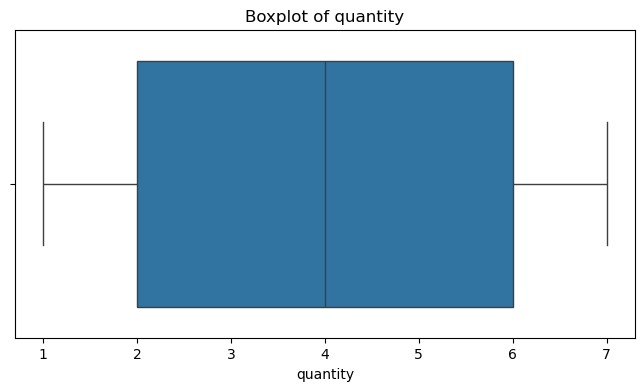

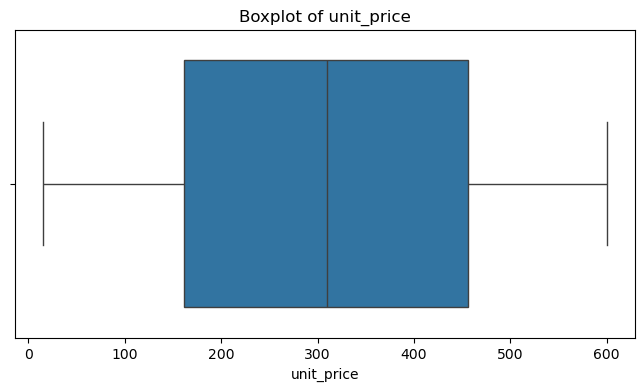

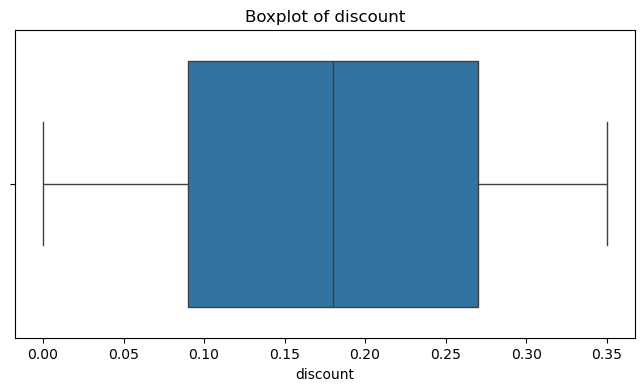

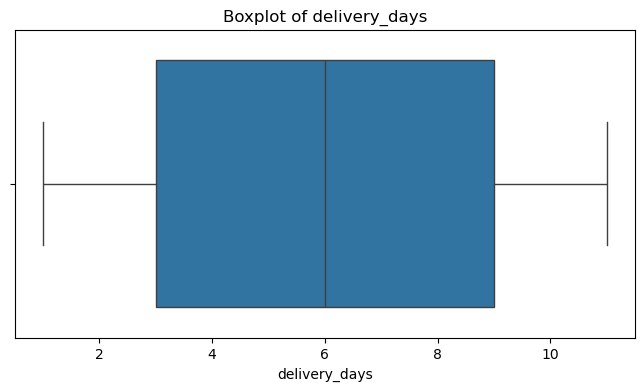

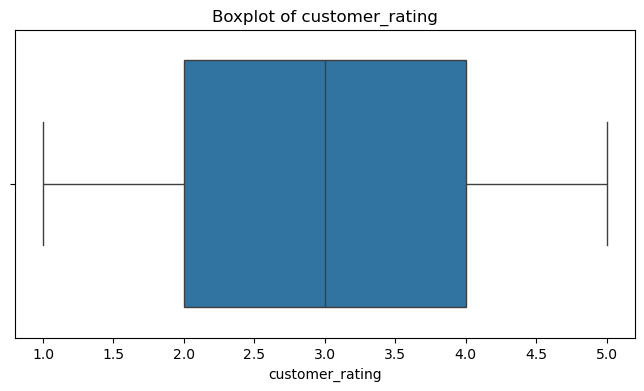

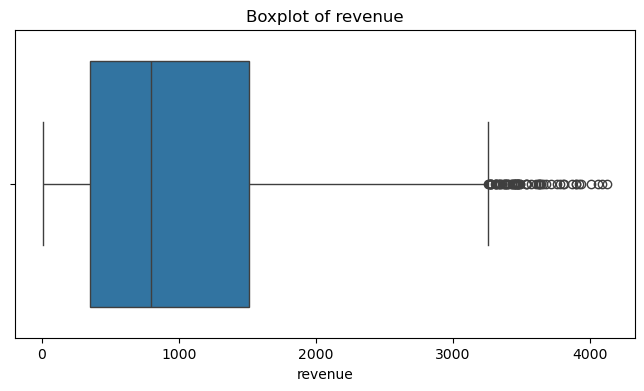

In [25]:
columns = ['quantity','unit_price','discount','delivery_days','customer_rating','revenue']
for col in columns:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=sales_data[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

Outlier for revenue is around or over 3300, and the data looks like:

In [26]:
sales_data[sales_data.revenue>3300].count()[0]

C:\Users\Dell\AppData\Local\Temp\ipykernel_8572\3183748651.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sales_data[sales_data.revenue>3300].count()[0]


np.int64(60)

It shows that there are 60 outliers in the data

In [27]:
sales_data[sales_data.revenue>3300].head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
39,10040,2022-02-09,1474,Home,North,7,584.36,0.11,Card,6,1.3,3640.56
69,10070,2022-03-11,1241,Beauty,East,7,567.75,0.16,Card,1,4.5,3338.37
102,10103,2022-04-13,1201,Clothing,West,6,586.65,0.02,COD,8,4.1,3449.50
126,10127,2022-05-07,1379,Clothing,South,7,506.18,0.02,Wallet,7,2.9,3472.39
157,10158,2022-06-07,1779,Electronics,North,7,571.07,0.02,COD,10,4.5,3917.54


##### Calculating revenue again using valid formula, to detect if the outlier is due to logical error or not 

In [28]:
sales_data['calculated_revenue'] = sales_data.quantity * sales_data.unit_price * (1-sales_data.discount)
sales_data['calculated_revenue'] = sales_data['calculated_revenue'].round(2)

In [29]:
sales_data.loc[sales_data['revenue'] == sales_data['calculated_revenue']].sort_values(by="order_id" ).count()[0]

C:\Users\Dell\AppData\Local\Temp\ipykernel_8572\1737988109.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sales_data.loc[sales_data['revenue'] == sales_data['calculated_revenue']].sort_values(by="order_id" ).count()[0]


np.int64(5000)

##### Since after recalculating revenue, the previous revenue and the current revenue turned out to be same so there is no data problem, outliers may arised due to high price product or large quantity orders.

In [30]:
sales_data[sales_data['revenue'] > 3300][['quantity','unit_price','product_category','revenue']].head(10)

,quantity,unit_price,product_category,revenue
39,7,584.36,Home,3640.56
69,7,567.75,Beauty,3338.37
102,6,586.65,Clothing,3449.50
126,7,506.18,Clothing,3472.39
157,7,571.07,Electronics,3917.54
178,7,598.63,Electronics,3394.23
241,7,550.20,Electronics,3427.75
256,7,507.39,Home,3445.18
321,7,585.43,Electronics,3893.11
369,7,529.25,Beauty,3630.66


In [31]:
    revenue_outliers = sales_data[sales_data['revenue']>3300]
    revenue_outliers['product_category'].value_counts()

product_category
Electronics    24
Clothing       15
Home           11
Beauty         10
Name: count, dtype: int64

In [32]:
sales_data.groupby('product_category')['revenue'].describe()

,count,mean,std,min,25%,50%,75%,max
product_category,,,,,,,,
Beauty,723.0,1059.281992,867.590231,20.94,331.585,821.64,1662.825,4005.93
Clothing,1531.0,1000.608570,806.210745,11.21,349.940,785.22,1477.230,3928.63
Electronics,1777.0,1029.768835,831.796825,13.26,365.670,796.49,1499.280,4119.33
Home,969.0,1013.502497,812.271060,13.01,348.350,802.83,1488.750,3640.56


In [33]:
revenue_outliers[['product_category','quantity','unit_price','discount','revenue']].sort_values('revenue',ascending = False)

,product_category,quantity,unit_price,discount,revenue
809,Electronics,7,594.42,0.01,4119.33
4883,Electronics,7,583.31,0.00,4083.17
2214,Electronics,7,591.15,0.02,4055.29
3101,Beauty,7,596.12,0.04,4005.93
3686,Clothing,7,578.59,0.03,3928.63
157,Electronics,7,571.07,0.02,3917.54
3349,Electronics,7,574.15,0.03,3898.48
321,Electronics,7,585.43,0.05,3893.11
661,Clothing,7,581.67,0.05,3868.11
4305,Beauty,7,555.09,0.02,3807.92


In [34]:
sales_data[sales_data['revenue'] < 3200][['quantity','unit_price','discount','product_category','revenue']]

,quantity,unit_price,discount,product_category,revenue
0,7,373.65,0.28,Beauty,1883.20
1,7,47.74,0.09,Clothing,304.10
2,3,311.28,0.31,Beauty,644.35
3,5,524.47,0.02,Electronics,2569.90
4,5,139.87,0.33,Clothing,468.56
...,...,...,...,...,...
4995,2,371.74,0.27,Clothing,542.74
4996,3,553.67,0.14,Beauty,1428.47
4997,3,77.22,0.24,Beauty,176.06
4998,4,138.41,0.21,Electronics,437.38


Here,High revenue can occur when customers purchase a large quantity (6-7) or when the product has a high unit price(500-600) while discount seems to be low, between 0 to 19%. The revenue values match the quantity, price, and discount, so they appear to be valid transactions. Therefore, I kept these outliers in the dataset.

### Finding the categories of product.

In [35]:
sales_data.product_category.unique()

array(['Beauty', 'Clothing', 'Electronics', 'Home'], dtype=object)

### What are the different payment methods?

In [36]:
sales_data.payment_method.unique()

array(['Wallet', 'Card', 'COD'], dtype=object)

### From which region customers are ordering from?

In [37]:
sales_data.region.unique()

array(['South', 'East', 'West', 'North'], dtype=object)

In [38]:
%pwd

'C:\\Users\\Dell\\projects\\ecommerce_sales_analysis'

### column containing categorical data

In [39]:
cat_data =  [col for col in sales_data.columns if sales_data[col].dtype == 'object']
cat_data

['product_category', 'region', 'payment_method']

### column containing numerical data

In [40]:
numerical_data = [col for col in sales_data.columns 
                  if sales_data[col].dtype != 'object']
numerical_data

['order_id',
 'order_date',
 'customer_id',
 'quantity',
 'unit_price',
 'discount',
 'delivery_days',
 'customer_rating',
 'revenue',
 'calculated_revenue']

## EDA Of Sales Data

#### Overall sales analysis

##### Total Revenue

In [41]:
sales_data['revenue'].sum()

np.float64(5109775.74)

##### Average revenue per order

In [42]:
sales_data.groupby('order_id')['revenue'].mean()

order_id
10001    1883.20
10002     304.10
10003     644.35
10004    2569.90
10005     468.56
          ...   
14996     542.74
14997    1428.47
14998     176.06
14999     437.38
15000    1069.90
Name: revenue, Length: 5000, dtype: float64

### How many orders are there

In [43]:
sales_data['order_id'].count()

np.int64(5000)

There are 5000 orders placed.

#### How many unique customers are there

In [44]:
sales_data['customer_id'].nunique()

989

There are 989 unique customers.

#### Total quantity of sold products

In [45]:
sales_data.quantity.sum()

np.int64(20224)

In [46]:
!git status

On branch main
Your branch and 'origin/main' have diverged,
and have 3 and 4 different commits each, respectively.
  (use "git pull" if you want to integrate the remote branch with yours)

Changes not staged for commit:
  (use "git add/rm <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   .ipynb_checkpoints/ecommerce_sales_anlaysis-checkpoint.ipynb
	deleted:    .ipynb_checkpoints/sales_visualization-checkpoint.ipynb
	deleted:    ecommerce_sales_analysis/.ipynb_checkpoints/ecommerce_sales_anlaysis-checkpoint.ipynb
	deleted:    ecommerce_sales_analysis/ecommerce_sales.csv
	modified:   ecommerce_sales_anlaysis.ipynb
	deleted:    netflix_data_analysis/.ipynb_checkpoints/netflix_data-checkpoint.ipynb
	deleted:    netflix_data_analysis/NetFlix.csv
	deleted:    netflix_data_analysis/netflix_data.ipynb

no changes added to commit (use "git add" and/or "git commit -a")


In [47]:
!cd

C:\Users\Dell\projects\ecommerce_sales_analysis


In [48]:
# !git add ecommerce_sales_anlaysis.ipynb

In [49]:
# !git commit -m "Update Ecommerce sales analysis"
# !git push origin main


### Product Category Analysis

#### Product category that gives highest total revenue.

In [50]:
# This will give all products according to max to minimum revenue
# product_category_revenue = sales_data.groupby('product_category')['revenue'].sum().sort_values(ascending=False)

# This will provide the category of the index with max revenue.
product_category_revenue = sales_data.groupby('product_category')['revenue'].sum()
product_category_revenue.idxmax(),product_category_revenue.max()

('Electronics', 1829899.22)

### Product with highest numbers of orders

In [51]:
highest_orders = sales_data.groupby('product_category')['order_id'].count()
highest_orders.idxmax(),highest_orders.max()


('Electronics', 1777)

#### Product category with highest quantity sold

In [52]:

highest_orders = sales_data.groupby('product_category')['quantity'].sum()
highest_orders.idxmax(),highest_orders.max()


('Electronics', 7109)

**Electronics is the best-performing product category**. It has the highest number of orders (1,777), the highest quantity sold (7,109 units), and the highest total revenue (1,829,899.22).
This shows that Electronics products have the highest customer demand and contribute the most to the overall revenue.

### Highest average revenue per order

In [53]:
avg_revenue_per_order = sales_data.groupby('product_category')['revenue'].mean()
avg_revenue_per_order.idxmax(),avg_revenue_per_order.max()


('Beauty', 1059.2819917012448)

### Product category with highest average customer rating 

In [54]:
avg_customer_rating = sales_data.groupby('product_category')['customer_rating'].mean()
avg_customer_rating.idxmax(),avg_customer_rating.max()

('Beauty', 3.008990318118949)

Although Electronics generates the highest total revenue, **Beauty has the highest average revenue per order and the highest average customer rating**. This suggests that Beauty products generate more revenue per order and receive relatively better customer.

### Regional Analysis

#### Region that generates the highest total revenue

In [55]:
region_wise_revenue = sales_data.groupby('region')['revenue'].sum()
region_wise_revenue.idxmax(),region_wise_revenue.max()

('West', 1345582.16)

#### Region that has highest number of orders

In [56]:
region_wise_orders = sales_data.groupby('region')['order_id'].count()
region_wise_orders.idxmax(),region_wise_orders.max()

('West', 1289)

#### Region that sells highest quantity 

In [57]:
region_wise_quantity = sales_data.groupby('region')['quantity'].sum()
region_wise_quantity.idxmax(),region_wise_quantity.max()

('West', 5260)

#### Region with highest average revenue per order

In [58]:
region_wise_avg_revenue = sales_data.groupby('region')['revenue'].mean()
region_wise_avg_revenue.idxmax(),round(region_wise_avg_revenue.max(),2)

('West', 1043.9)

#### Region with highest average customer rating

In [59]:
region_wise_avg_rating = sales_data.groupby('region')['customer_rating'].mean()
region_wise_avg_rating.idxmax(),round(region_wise_avg_rating.max())

('North', 3)

#### Region with longest average delivery time

In [60]:
region_wise_delivery = sales_data.groupby('region')['delivery_days'].mean()
region_wise_delivery.idxmax(),round(region_wise_delivery.max())

('South', 6)


The **West region performs the best overall** because it has the highest revenue, number of orders, quantity sold, and average customer rating. On the other hand, the **South region has the longest average delivery time of 6 days**, so its delivery service may need improvement.


### Customer Analysis

#### Customers who have placed the most orders

In [61]:
customer_orders = sales_data.groupby('customer_id')['order_id'].count()
customer_orders.idxmax(),customer_orders.max()
# customer_orders.sort_values(ascending=False)

(np.int64(1663), 14)

#### Which customers have generated the highest revenue

In [62]:
customer_revenue = sales_data.groupby('customer_id')['revenue'].sum()
customer_revenue.idxmax(),customer_revenue.max()

(np.int64(1663), 17680.69)

#### What is the average revenue generated per customer?

In [63]:
customer_avg_revenue = sales_data.groupby('customer_id')['revenue'].mean()
customer_avg_revenue.idxmax(),customer_avg_revenue.max()

(np.int64(1463), 2890.44)

**Customer with id 1663** placed the highest number of orders contributing more towards highest total revenue.

#### Which customers are the highest-value customers?

In [64]:
high_value_customer = sales_data.groupby('customer_id')['revenue'].sum().sort_values(ascending=False).head(10)
high_value_customer

customer_id
1663    17680.69
1955    16265.15
1675    15036.46
1276    15023.71
1647    14894.97
1804    14330.98
1193    14151.65
1836    14110.78
1957    13956.95
1735    13146.25
Name: revenue, dtype: float64

### Time Analysis

In [ ]:
How does revenue change over time?

In [118]:
data = sales_data.groupby(sales_data['order_date'].dt.year)['revenue'].sum()
# sns.lineplot(sales_data,x='order_date',y='revenue')
data

order_date
2022    371824.30
2023    365915.79
2024    363209.13
2025    349802.33
2026    386369.69
2027    386151.91
2028    376844.80
2029    359239.24
2030    387884.46
2031    365250.83
2032    386584.63
2033    408725.72
2034    363239.55
2035    238733.36
Name: revenue, dtype: float64

In [122]:
monthly_sales_data = sales_data.groupby(sales_data['order_date'].dt.month)['revenue'].sum()
monthly_sales_data

order_date
1     426374.92
2     413890.24
3     425050.52
4     398715.16
5     479772.55
6     442941.58
7     440570.72
8     460874.78
9     402368.11
10    407873.12
11    410657.88
12    400686.16
Name: revenue, dtype: float64

<Axes: xlabel='order_date', ylabel='revenue'>

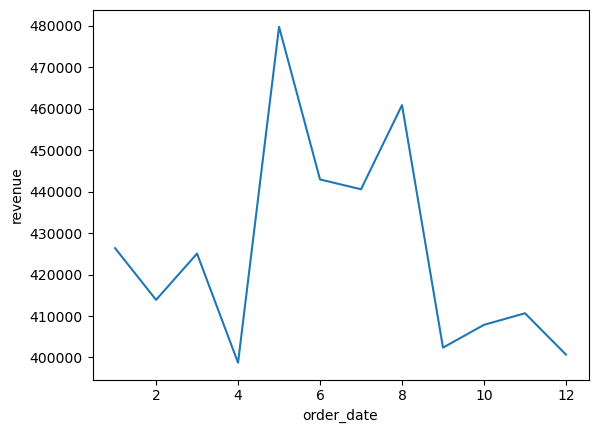

In [124]:
sns.lineplot(monthly_sales_data)

Revenue changes from month to month. **May has the highest revenue, while April has the lowest revenue**. Revenue generally remains around 400,000–480,000 across the months.

Text(0, 0.5, 'Revenue')

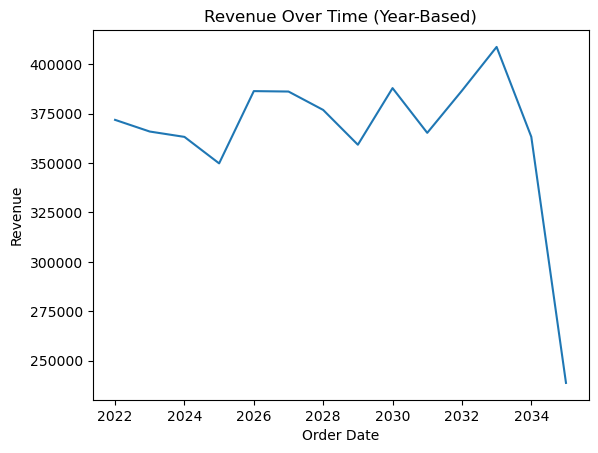

In [119]:
sns.lineplot(data)
plt.title('Revenue Over Time (Year-Based)')
plt.xlabel('Order Date')
plt.ylabel('Revenue')

Revenue fluctuates over the years. It decreases from 2022 to 2025, rises significantly from 2025 to 2026, remains **almost stable in 2027**, and then continues to fluctuate. Revenue reaches its **highest point around 2033**, followed by a sharp decline in 2034–2035.

In [125]:
monthly_sales = sales_data.groupby(
    [sales_data['order_date'].dt.year,
     sales_data['order_date'].dt.month]
)['revenue'].sum()

monthly_sales

order_date  order_date
2022        1             35624.89
            2             29908.89
            3             30309.28
            4             30781.96
            5             41629.24
                            ...   
2035        5             33393.87
            6             25205.26
            7             23944.48
            8             29354.74
            9              4952.23
Name: revenue, Length: 165, dtype: float64

In [129]:
sales_data['year_month'] = sales_data['order_date'].dt.to_period('M')
monthly_sales = sales_data.groupby('year_month')['revenue'].sum()

monthly_sales

year_month
2022-01    35624.89
2022-02    29908.89
2022-03    30309.28
2022-04    30781.96
2022-05    41629.24
             ...   
2035-05    33393.87
2035-06    25205.26
2035-07    23944.48
2035-08    29354.74
2035-09     4952.23
Freq: M, Name: revenue, Length: 165, dtype: float64

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,calculated_revenue,year_month
0,10001,2022-01-01,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20,1883.20,2022-01
1,10002,2022-01-02,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10,304.10,2022-01
2,10003,2022-01-03,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35,644.35,2022-01
3,10004,2022-01-04,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90,2569.90,2022-01
4,10005,2022-01-05,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56,468.56,2022-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,14996,2035-09-05,1289,Clothing,West,2,371.74,0.27,COD,3,2.3,542.74,542.74,2035-09
4996,14997,2035-09-06,1294,Beauty,North,3,553.67,0.14,COD,11,2.2,1428.47,1428.47,2035-09
4997,14998,2035-09-07,1450,Beauty,West,3,77.22,0.24,Wallet,6,3.4,176.06,176.06,2035-09
4998,14999,2035-09-08,1903,Electronics,South,4,138.41,0.21,COD,4,2.8,437.38,437.38,2035-09


### Relationship Analysis

In [66]:
sales_data.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,calculated_revenue
0,10001,2022-01-01,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20,1883.20
1,10002,2022-01-02,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10,304.10
2,10003,2022-01-03,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35,644.35
3,10004,2022-01-04,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90,2569.90
4,10005,2022-01-05,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56,468.56


In [68]:
sales_data['quantity'].corr(sales_data['revenue'])

np.float64(0.6235641472826254)

Text(0, 0.5, 'Revenue')

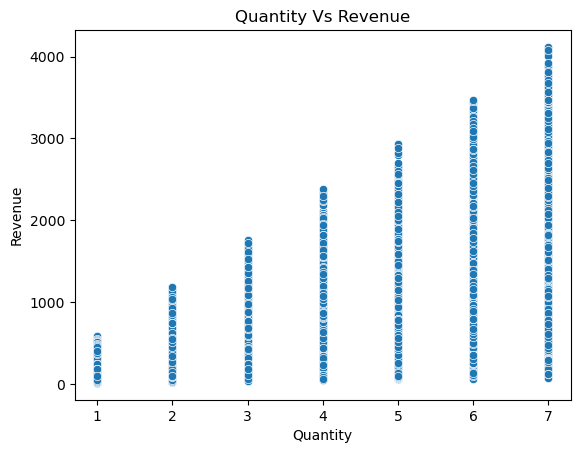

In [69]:
sns.scatterplot(data=sales_data,x='quantity',y='revenue')
plt.title('Quantity Vs Revenue')
plt.xlabel('Quantity')
plt.ylabel('Revenue')

Quantity has **positive relationship** with revenue,we can see that when **quantity of products is increasing revenue is also increasing**.


In [71]:
sales_data['unit_price'].corr(sales_data.revenue)

np.float64(0.678032373602438)

Text(0, 0.5, 'Revenue')

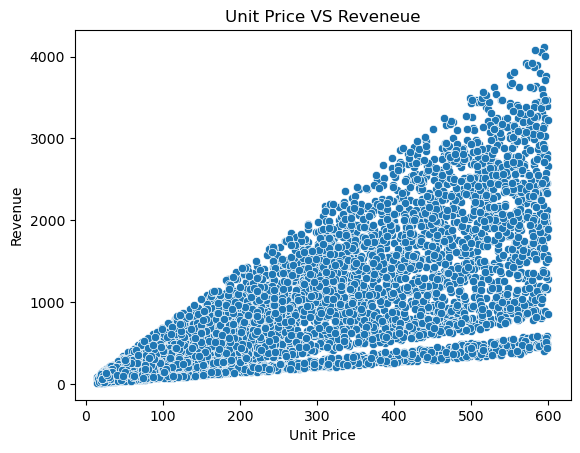

In [72]:
sns.scatterplot(sales_data,x='unit_price',y='revenue')
plt.title('Unit Price VS Reveneue')
plt.xlabel('Unit Price')
plt.ylabel('Revenue')

There is a **positive relationship** between unit price and revenue. **As unit price increases, revenue generally increases**. However, the points are widely spread because quantity and discount also affect revenue.

In [65]:
# !git add ecommerce_sales_analysis
# !git commit -m "Added Regional analysis"
# !git push origin main